In [42]:
import numpy as np

rng = np.random.default_rng(seed=1)

num_samples_per_class = 1000
negative_samples = rng.multivariate_normal(
    mean=[0, 3],
    cov=[
        [1, 0.5],
        [0.5, 1],
    ],
    size=num_samples_per_class,
)
positive_samples = rng.multivariate_normal(
    mean=[3, 0],
    cov=[
        [1, 0.5],
        [0.5, 1],
    ],
    size=num_samples_per_class,
)

inputs = np.vstack((negative_samples, positive_samples)).astype("float32")
targets = np.vstack(
    (
        np.zeros((num_samples_per_class, 1), dtype="float32"),
        np.ones((num_samples_per_class, 1), dtype="float32"),
    )
)


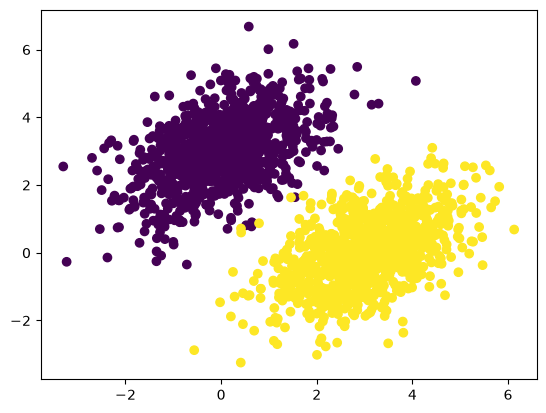

In [43]:
import matplotlib.pyplot as plt

plt.scatter(inputs[:, 0], inputs[:, 1], c=targets[:, 0] > 0.5)
plt.show()

In [44]:
import tensorflow as tf

rng_tf = tf.random.Generator.from_seed(seed=1)

input_dim = 2
output_dim = 1

W = tf.Variable(initial_value=rng_tf.uniform(shape=(input_dim, output_dim), dtype="float32"))
b = tf.Variable(initial_value=tf.zeros((output_dim,), dtype="float32"))

In [45]:
def model(inputs, W, b):
    return tf.matmul(inputs, W) + b

In [46]:
def mean_squared_error(targets, predictions):
    per_sample_losses = tf.square(targets - predictions)
    return tf.reduce_mean(per_sample_losses)

In [47]:
learning_rate = 0.1


def training_step(inputs, targets, W, b):
    with tf.GradientTape() as tape:
        predictions = model(inputs, W, b)
        loss = mean_squared_error(targets, predictions)
    grad_W_wrt_loss, grad_b_wrt_loss = tape.gradient(loss, [W, b])
    W.assign_sub(learning_rate * grad_W_wrt_loss)
    b.assign_sub(learning_rate * grad_b_wrt_loss)
    return loss


In [48]:
for step in range(50):
    loss = training_step(inputs, targets, W, b)
    print(f"Loss at step {step}: {loss:.4f}")

Loss at step 0: 2.7246
Loss at step 1: 0.4896
Loss at step 2: 0.1760
Loss at step 3: 0.1252
Loss at step 4: 0.1114
Loss at step 5: 0.1033
Loss at step 6: 0.0965
Loss at step 7: 0.0904
Loss at step 8: 0.0848
Loss at step 9: 0.0797
Loss at step 10: 0.0751
Loss at step 11: 0.0708
Loss at step 12: 0.0669
Loss at step 13: 0.0633
Loss at step 14: 0.0601
Loss at step 15: 0.0571
Loss at step 16: 0.0544
Loss at step 17: 0.0519
Loss at step 18: 0.0496
Loss at step 19: 0.0475
Loss at step 20: 0.0456
Loss at step 21: 0.0439
Loss at step 22: 0.0423
Loss at step 23: 0.0408
Loss at step 24: 0.0395
Loss at step 25: 0.0383
Loss at step 26: 0.0372
Loss at step 27: 0.0361
Loss at step 28: 0.0352
Loss at step 29: 0.0344
Loss at step 30: 0.0336
Loss at step 31: 0.0329
Loss at step 32: 0.0322
Loss at step 33: 0.0316
Loss at step 34: 0.0311
Loss at step 35: 0.0306
Loss at step 36: 0.0301
Loss at step 37: 0.0297
Loss at step 38: 0.0293
Loss at step 39: 0.0290
Loss at step 40: 0.0287
Loss at step 41: 0.0284
Lo

In [49]:
predictions = model(inputs, W, b)
predicted_classes = predictions > 0.5
accuracy = np.mean(predicted_classes == targets)
print(f"Accuracy: {accuracy:.2%}")

Accuracy: 99.75%


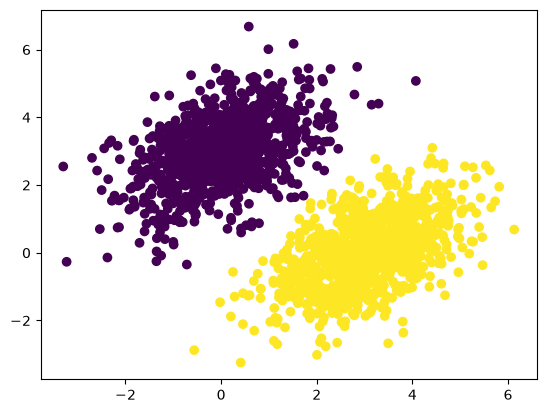

In [50]:
plt.scatter(inputs[:, 0], inputs[:, 1], c=predictions[:, 0] > 0.5)